# Phishing website detection: from 71% to 97%, and why 97% is not the whole story

**Goal:** flag phishing websites while keeping false alarms on legitimate sites under **1%**, because a filter that
blocks real sites gets switched off.

**Data:** Vrbančič et al. (2020), 88,647 websites (58,000 legitimate, 30,647 phishing), 111 features describing
the URL string (counts of `.`, `-`, `/`… in each URL component) and the domain (age, DNS, TLS, redirects).

**Contents**
1. Data audit: duplicates, `-1` values, dead features
2. What went wrong in v1
3. The shortcut: legitimate URLs are mostly homepages
4. Models: URL-only vs full, compared at a fixed false-positive budget
5. Fixing the operating threshold for deep links
6. Explanations, and what they reveal about the shortcut
7. The URL scanner in action
8. Limitations

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display
from phishguard.data import load_raw, clean, has_path, TARGET, FEATURE_SETS, DEAD_FEATURES
from phishguard.predict import scan_url

FIG = ROOT / "reports" / "figures"
M = json.loads((ROOT / "reports" / "metrics.json").read_text())
raw = load_raw()
print(raw.shape, raw[TARGET].value_counts().to_dict())

(88647, 112) {0: 58000, 1: 30647}


## 1. Data audit

In [2]:
print("Exact duplicate rows:", raw.duplicated().sum())
minus_one = (raw.drop(columns=TARGET) == -1).mean().sort_values(ascending=False)
print("Columns using -1:", (minus_one > 0).sum(), "| NaN values:", raw.isna().sum().sum())
minus_one.head(8).round(3).to_frame("share of -1")

Exact duplicate rows: 1438


Columns using -1: 66 | NaN values: 0


,share of -1
qty_questionmark_params,0.916
qty_equal_params,0.916
qty_at_params,0.916
qty_and_params,0.916
qty_exclamation_params,0.916
qty_space_params,0.916
qty_tilde_params,0.916
qty_comma_params,0.916


* **1,438 exact duplicates.** v1 ran `data.drop_duplicates()` without saving the result back to `data`, so they stayed in and could land in both
  training and test data.
* **Missing values are encoded as `-1`, not NaN**, so v1's `dropna()` removed nothing. `-1` means *the URL
  has no such component* (e.g. no query string → all 20 `params` features are −1) or *the lookup failed*. For tree
  models it is a perfectly good value; for logistic regression it is converted to NaN + a missing-indicator.

In [3]:
raw.groupby(TARGET)[DEAD_FEATURES].agg(lambda s: (s == 0).mean()).round(4).rename(columns=lambda c: c + " (share of 0)")

,url_google_index (share of 0),domain_google_index (share of 0)
phishing,,
0,0.9951,0.9950
1,0.9993,0.9979


The two Google-index features are ~100% zero in **both** classes. The look-ups evidently failed when the data was collected, so they're dropped.

In [4]:
df, report = clean(raw)
print(report)

- Removed 1,438 exact duplicate rows (v1 called drop_duplicates() without assigning the result)
- Removed 12 rows whose identical feature vectors carry both labels
- Dropped 2 dead features ['url_google_index', 'domain_google_index'] (≈99.8% zeros in both classes)
- Kept -1 as an explicit 'absent / lookup failed' value; NOT dropped by dropna() because it is not NaN
- Final: 87,197 rows, 35.0% phishing


## 2. What went wrong in v1
The original notebook selected features with
```python
selected_features = correlation_matrix[correlation_matrix['url_shortened'].abs() > 0.1].index
```
which keeps features correlated with **`url_shortened`**, not with the target `phishing`. Only 3 features survived:

In [5]:
v1 = M["baselines"]["v1_method"]
print("v1 features:", v1["features_used"])
pd.Series({k: v1[k] for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]}).round(3).to_frame("v1 method on our test set")

v1 features: ['qty_vowels_domain', 'domain_length', 'url_shortened']


,v1 method on our test set
accuracy,0.700
precision,0.628
recall,0.350
f1,0.450
roc_auc,0.711


Re-running v1's method on this project's test set reproduces its result (70% accuracy vs 70.9% originally), with **recall 35%**, meaning it misses 2 of every 3 phishing sites.

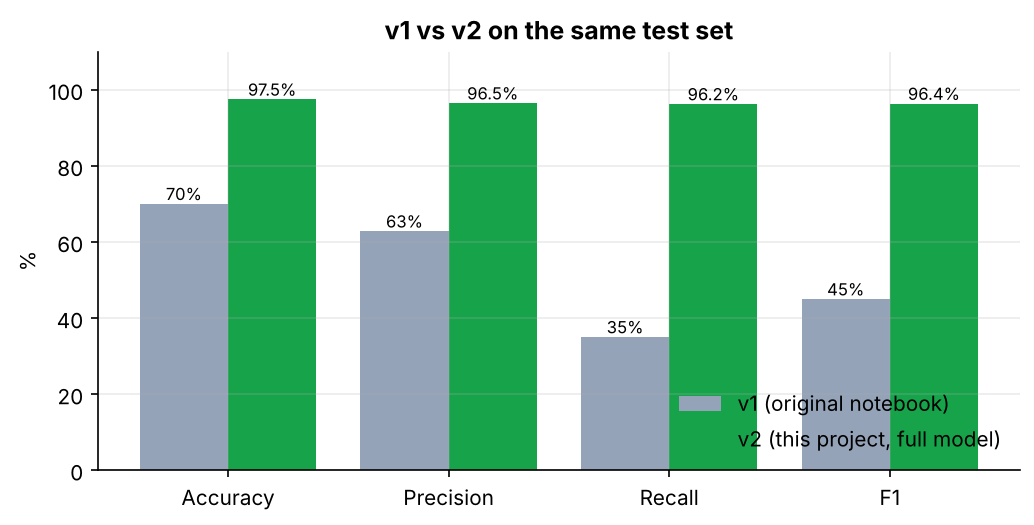

In [6]:
display(Image(FIG / "v1_vs_v2.png", width=650))

## 3. The shortcut: legitimate URLs are mostly homepages

In [7]:
pd.crosstab(has_path(df).map({True: "has a path", False: "homepage only"}), df[TARGET].map({0: "legitimate", 1: "phishing"}),
            normalize="columns").round(3)

phishing,legitimate,phishing
directory_length,,
has a path,0.196,0.976
homepage only,0.804,0.024


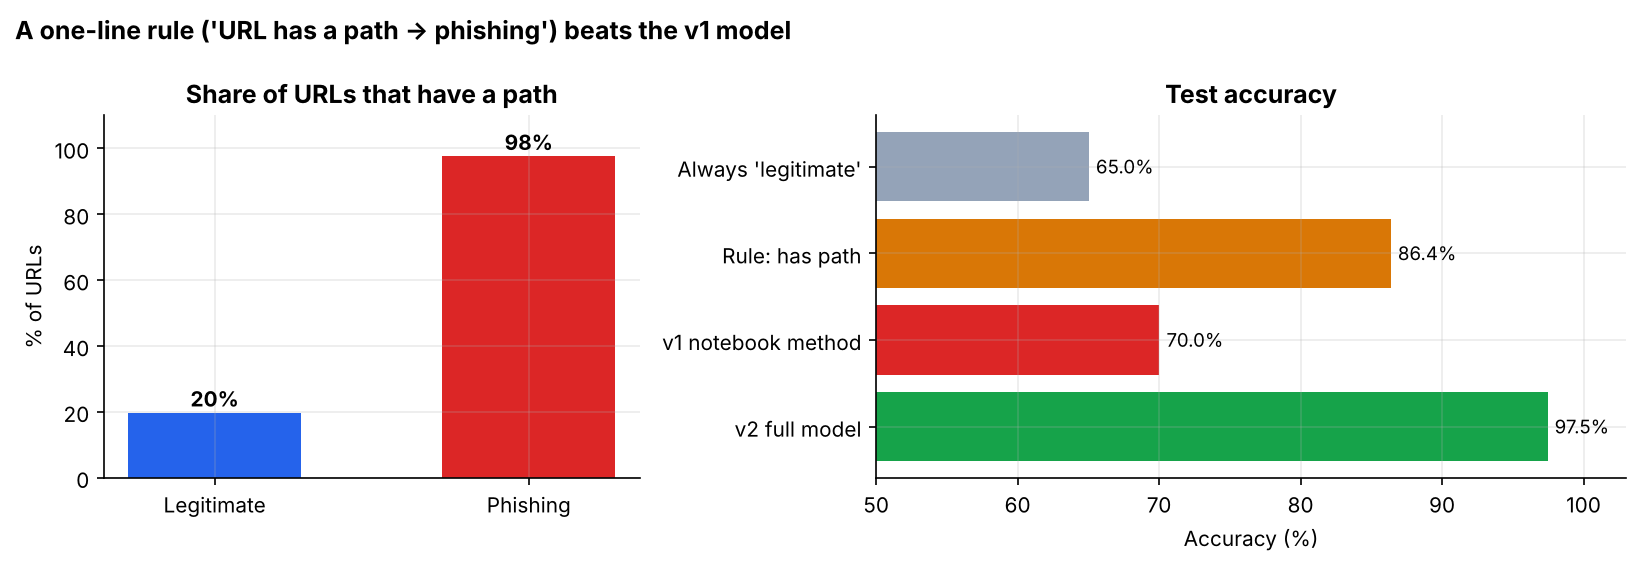

has-path rule accuracy: 86.4%


In [8]:
display(Image(FIG / "shortcut.png", width=900))
b = M["baselines"]; print(f"has-path rule accuracy: {b['has_path_rule_accuracy']:.1%}")

**80% of legitimate URLs are bare homepages, while 98% of phishing URLs have a path.** The dataset paired
phishing links (which point at a specific fake login page) with legitimate *domains*. A one-line rule,
"has a path → phishing", scores **86% accuracy** without any machine learning.

That matters because in real life people click legitimate deep links all day (`github.com/…/README.md`,
`amazon.com/dp/…`). A model that has learned "path = phishing" will raise false alarms on them. So from here on every
result is also reported **separately for homepages and deep links**, and deep links are the honest test.

## 4. Models: URL-only vs full, at a fixed false-positive budget

In [9]:
cv = pd.DataFrame(M["cv"])
cv.pivot(index="feature_set", columns="model", values="pr_auc").loc[["lexical", "network", "full"]].round(4)

model,lightgbm,logistic_regression,random_forest,xgboost
feature_set,,,,
lexical,0.9701,0.9445,0.9681,0.9702
network,0.9236,0.6854,0.9229,0.9199
full,0.9924,0.9656,0.9890,0.9920


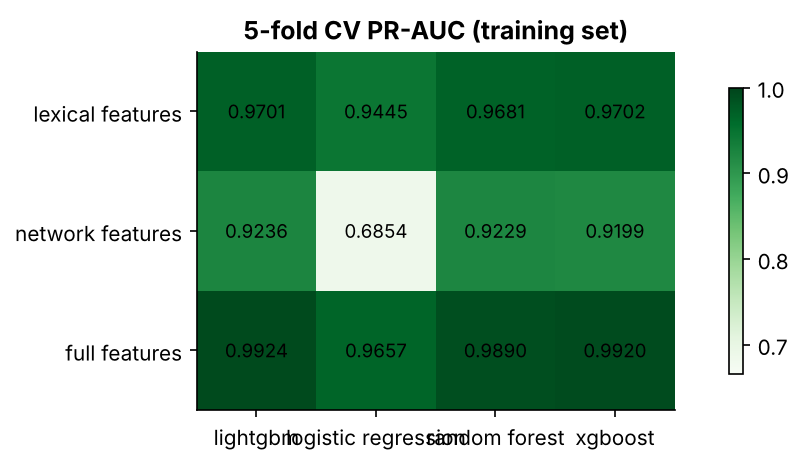

In [10]:
display(Image(FIG / "model_comparison.png", width=650))

* **Lexical (URL-only)** features let you check a link *before* it is opened (email gateway, browser extension).
* **Network** features (domain age, DNS, TLS, redirects) need look-ups, but add a lot.
* **Full** = both. Gradient boosting (LightGBM/XGBoost) wins in every column; logistic regression trails, a sign of
  strong non-linear interactions.

In [11]:
rows = []
for fs in ["lexical", "full"]:
    f = M["final"][fs]
    rows.append({"model": f"{fs} ({f['model']})", **{k: f["test"][k] for k in
                 ["roc_auc", "pr_auc", "tpr_at_1pct_fpr", "tpr_at_0.1pct_fpr", "accuracy", "precision", "recall", "fpr"]}})
pd.DataFrame(rows).set_index("model").round(4)

,roc_auc,pr_auc,tpr_at_1pct_fpr,tpr_at_0.1pct_fpr,accuracy,precision,recall,fpr
model,,,,,,,,
lexical (xgboost),0.9819,0.9716,0.7763,0.4372,0.9123,0.9792,0.7655,0.0087
full (lightgbm),0.9959,0.9930,0.9334,0.6717,0.9672,0.9842,0.9210,0.0079


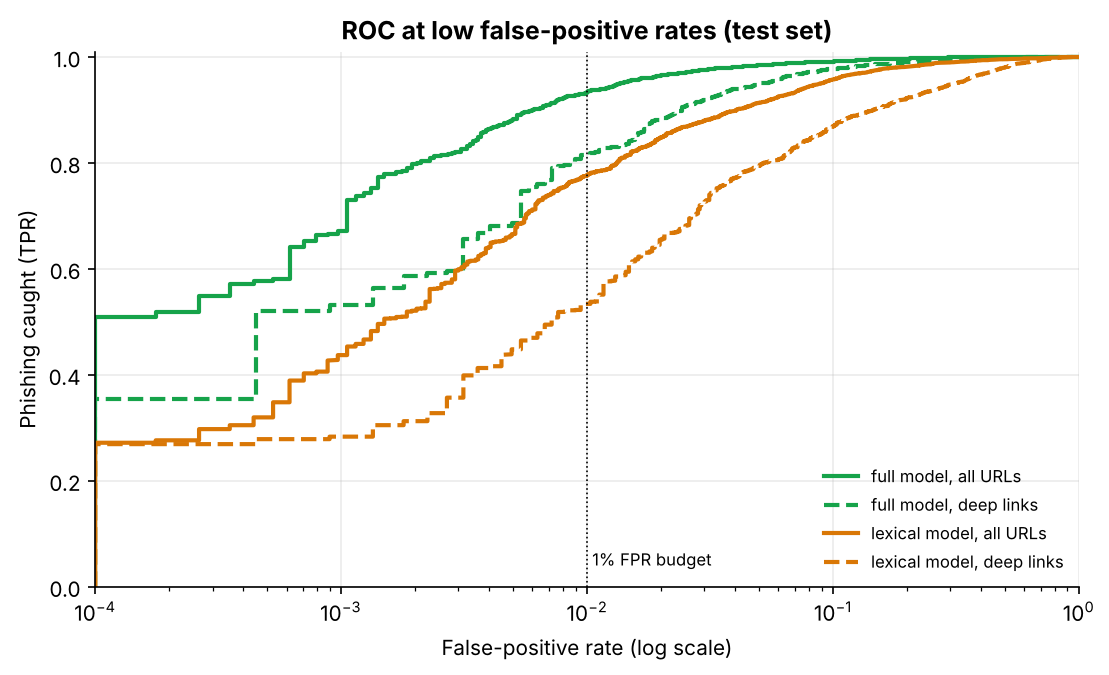

In [12]:
display(Image(FIG / "roc_low_fpr.png", width=700))

Note the log-scaled x-axis: at a **1% false-positive rate**, the full model catches ~93% of phishing sites overall,
the URL-only model ~78%. On **deep links** (dashed lines) both curves drop, which is the shortcut showing up.

## 5. Fixing the operating threshold for deep links

In [13]:
strat = pd.read_csv(ROOT / "reports" / "stratified_results.csv")
strat[strat.subset != "all URLs"].pivot_table(index=["model", "thresholds"], columns="subset",
                                               values=["recall", "fpr"]).round(3)

fpr               recall          
subset               deep links homepages deep links homepages
model   thresholds                                            
full    global            0.037     0.001      0.935     0.376
        per URL type      0.008     0.008      0.790     0.718
lexical global            0.044     0.000      0.784     0.020
        per URL type      0.015     0.010      0.603     0.168

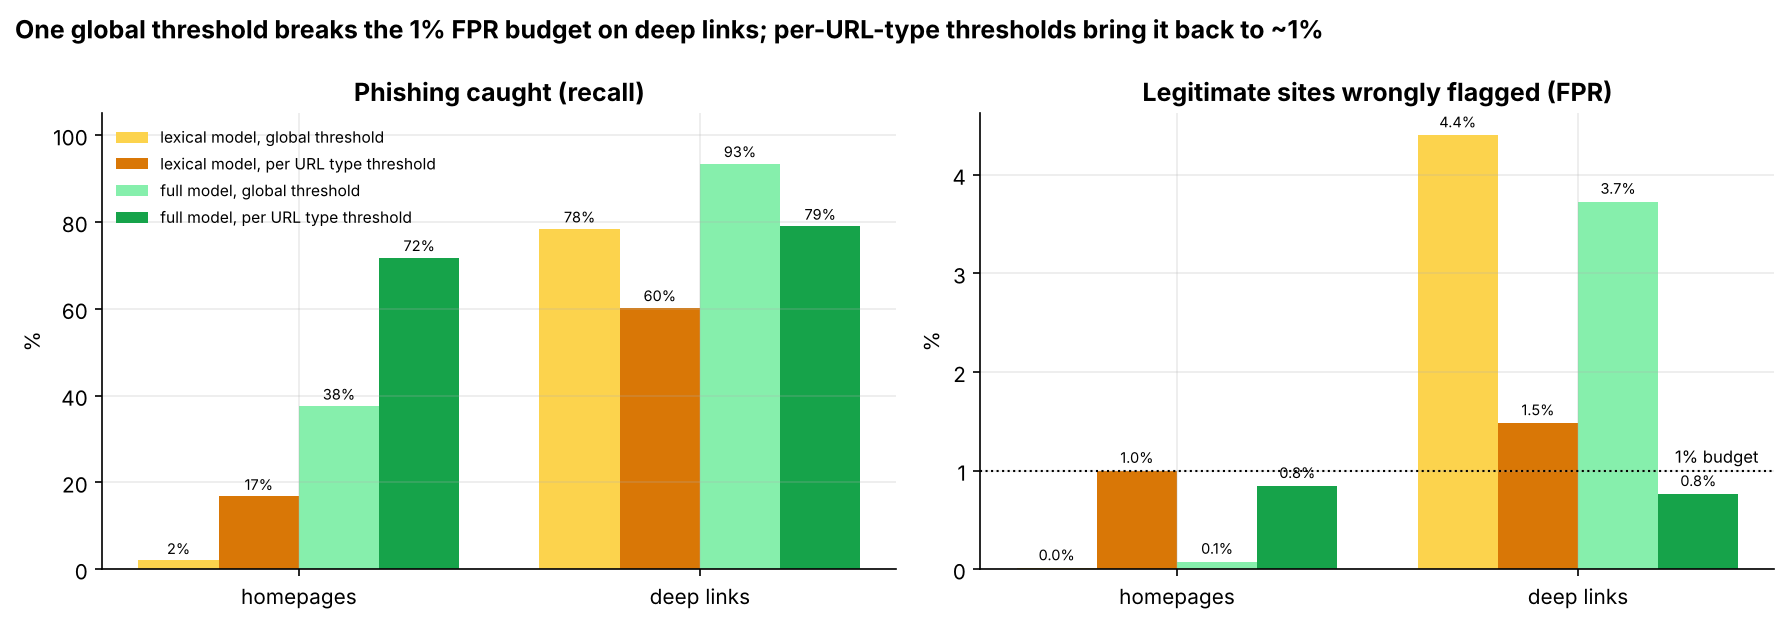

In [14]:
display(Image(FIG / "stratified_performance.png", width=950))

With **one global threshold** tuned to 1% FPR on the validation set, the budget is met *on average*, but only
because easy homepages dominate the legitimate class. On **legitimate deep links the real false-positive rate is
about 4× the budget**.

**Fix:** choose a separate threshold for each URL type (homepage / deep link), each at ≤ 1% FPR on validation.
The deep-link FPR returns to ~1%, at the cost of lower recall on deep links. That is the honest trade-off.
Both thresholds are stored with the model and applied automatically by the scanner and the API.

In [15]:
dl = M["deep_link_trained_full_model"]
print(f"Full model trained ONLY on deep links -> deep-link ROC-AUC {dl['roc_auc']:.4f} "
      f"(vs {[s for s in M['final']['full']['stratified'] if s['subset']=='deep links'][0]['roc_auc']:.4f} for the model trained on everything)")

Full model trained ONLY on deep links -> deep-link ROC-AUC 0.9874 (vs 0.9880 for the model trained on everything)


Training only on deep links gives the same deep-link performance, so the full model hasn't *only* learned the shortcut. It has real signal (domain age, DNS) on top.

## 6. Explanations, and what they reveal about the shortcut

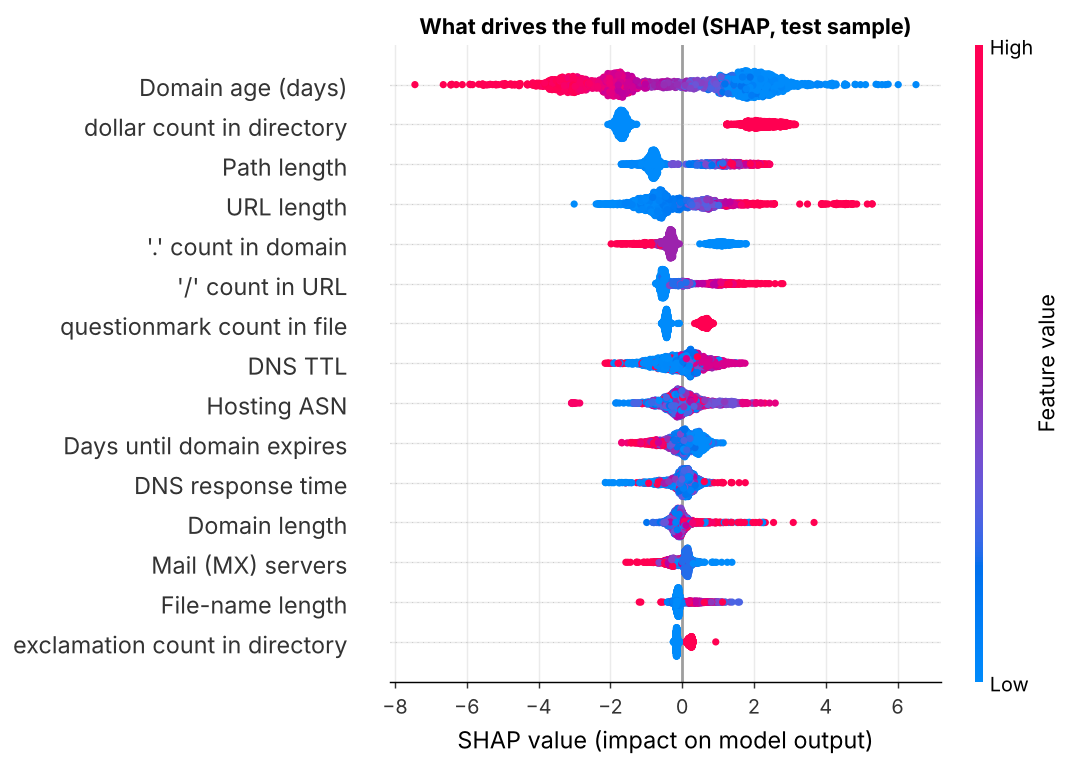

In [16]:
display(Image(FIG / "shap_full.png", width=750))

In [17]:
imp = pd.Series(M["shap_importance"]["full"]).head(8)
imp.to_frame("mean |SHAP|")

,mean |SHAP|
time_domain_activation,2.0805
qty_dollar_directory,1.9535
directory_length,0.9852
length_url,0.8801
qty_dot_domain,0.6127
qty_slash_url,0.5737
qty_questionmark_file,0.5292
ttl_hostname,0.4895


In [18]:
# Why is "$ count in the path" one of the most important features?
print(df.groupby(TARGET)["qty_dollar_directory"].value_counts().unstack(fill_value=0))

qty_dollar_directory    -1      0    1    2    3    4    5    6    8    9   \
phishing                                                                     
0                     45574  11132    0    0    0    0    0    0    0    0   
1                       745  29717   10    3    2    3    3    2    2    1   

qty_dollar_directory   10  
phishing                   
0                       0  
1                       3  


Almost no URL contains a `$`. The feature is important because its value is **−1 when there is no path and 0 when
there is one**, so it acts as a hidden "has a path" flag. SHAP surfaces the shortcut directly. Without explanations
you might ship this model believing it understands dollar signs.

The genuinely informative features are **domain age** (`time_domain_activation`: phishing domains are days to weeks
old), URL/path length, dots in the domain (sub-domain stuffing like `paypal.com.secure-login.xyz`) and DNS TTL.

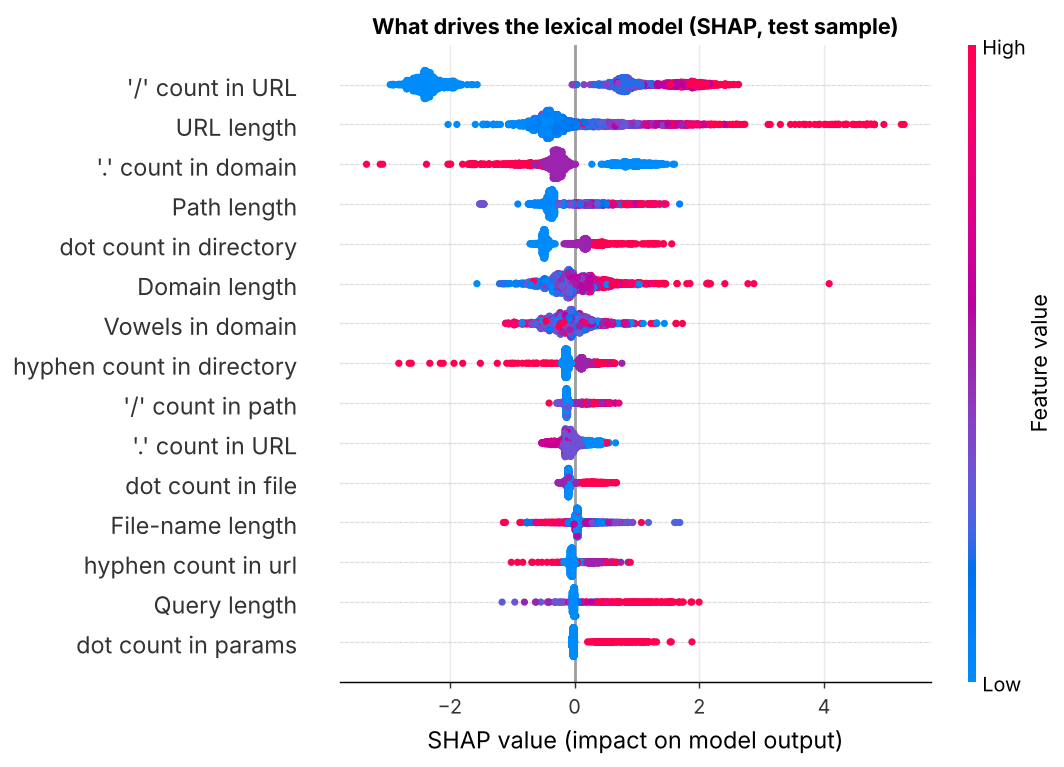

In [19]:
display(Image(FIG / "shap_lexical.png", width=750))

## 7. The URL scanner in action

In [20]:
urls = ["wikipedia.org",
        "http://paypal.com.account-verify.secure-login.xyz/signin/update.php?id=5531&session=a8f2",
        "http://192.168.10.24/bank/login/index.html",
        "http://github.com.login-session.app/auth",
        "https://docs.python.org/3/library/urllib.parse.html"]
pd.DataFrame([{k: r[k] for k in ["url", "registered_domain", "phishing_probability", "verdict", "threshold"]}
              for r in map(scan_url, urls)])

,url,registered_domain,phishing_probability,verdict,threshold
0,wikipedia.org,wikipedia.org,0.0233,trusted domain,0.1010
1,http://paypal.com.account-verify.secure-login....,secure-login.xyz,0.9970,phishing,0.9721
2,http://192.168.10.24/bank/login/index.html,192.168.10.24,0.9953,phishing,0.9721
3,http://github.com.login-session.app/auth,login-session.app,0.8824,suspicious,0.9721
4,https://docs.python.org/3/library/urllib.parse...,python.org,0.9816,trusted domain,0.9721


Look at the last row: the URL-only model gives a **legitimate Python docs page a phishing score near 1**.
This is the shortcut from section 3 in action. The dataset's legitimate deep links don't look like everyday
documentation or product pages, so on real traffic the URL-only false-positive rate will be *higher* than the
1.5% measured on the test set.

Production phishing filters never rely on a URL model alone. They add a **reputation layer** (allowlists of
well-known domains, domain-age checks). The scanner does the same: a small allowlist of registered domains
(`data/allowlist.txt`) short-circuits trusted sites, while look-alikes such as `github.com.login-session.app`
(registered domain `login-session.app`) still go through the model.

## 8. Limitations
* **Collection bias:** legitimate examples are mostly homepages, so absolute numbers are optimistic for real traffic.
  The deep-link results are the realistic ones.
* **No raw URLs or timestamps in the dataset**, so no temporal split (phishing evolves) and no de-duplication by
  domain (sibling URLs of one campaign may sit in train and test).
* **The URL feature extractor was reverse-engineered** from identities in the data (see `tests/test_url_features.py`).
  `qty_tld_url` and `tld_present_params` depend on an unknown TLD list and are approximate.
* Network features are a 2020 snapshot. The live scanner uses the URL-only model; scoring with the full model needs
  WHOIS/DNS/TLS look-ups (accepted via the `/score` API endpoint).

**Next steps:** collect fresh URLs (PhishTank / OpenPhish + Tranco top sites *including deep links*), validate the
extractor on them, test on future months (temporal drift), and add a live domain-intelligence collector.